# Kernel SVM From Scratch - Polynomial vs RBF

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
rng = np.random.default_rng(42)
n = 150
def ring(r, n):
    t = rng.uniform(0, 2 * np.pi, n)
    rad = r + rng.normal(0, 0.25, n)
    return np.c_[rad * np.cos(t), rad * np.sin(t)]

X = np.vstack([ring(1.0, n), ring(2.2, n)])
y = np.hstack([np.ones(n), -np.ones(n)])

idx = rng.permutation(len(X)); s = int(0.7 * len(X))
X_train, y_train, X_test, y_test = X[idx[:s]], y[idx[:s]], X[idx[s:]], y[idx[s:]]
print(X_train.shape, X_test.shape)

(210, 2) (90, 2)


In [3]:
def linear_kernel(A, B):
    return A @ B.T

def poly_kernel(A, B, degree=2, c=1.0):
    return (A @ B.T + c) ** degree

def rbf_kernel(A, B, gamma=0.5):
    sq = np.sum(A**2, 1)[:, None] + np.sum(B**2, 1)[None, :] - 2 * A @ B.T  
    return np.exp(-gamma * sq)

In [4]:
c = 1.0
def phi(x):
    return np.array([x[0]**2, x[1]**2, np.sqrt(2)*x[0]*x[1],
                     np.sqrt(2*c)*x[0], np.sqrt(2*c)*x[1], c])

x, z = X_train[0], X_train[1]
print('Explicit 6D dot product :', phi(x) @ phi(z))
print('Kernel trick (2D only)  :', poly_kernel(x[None], z[None], 2, c)[0, 0])

Explicit 6D dot product : 1.9730427363245489
Kernel trick (2D only)  : 1.9730427363245493


In [5]:
class KernelSVM:
    def __init__(self, kernel, C=1.0, epochs=100):
        self.kernel, self.C, self.epochs = kernel, C, epochs

    def fit(self, X, y):
        self.X, self.y = X, y
        K = self.kernel(X, X) + 1                 
        Q = np.outer(y, y) * K
        a = np.zeros(len(y))
        for _ in range(self.epochs):
            for i in range(len(y)):
                g = 1 - Q[i] @ a                    
                a[i] = np.clip(a[i] + g / Q[i, i], 0, self.C)  
        self.a = a
        return self

    def decision_function(self, X):
        return (self.a * self.y) @ (self.kernel(self.X, X) + 1)

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

In [6]:
models = {
    'Linear':     KernelSVM(linear_kernel, C=1.0),
    'Polynomial': KernelSVM(lambda A, B: poly_kernel(A, B, degree=2, c=1.0), C=1.0),
    'RBF':        KernelSVM(lambda A, B: rbf_kernel(A, B, gamma=0.5), C=1.0),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print(f'{name:11s} train acc = {accuracy(y_train, m.predict(X_train)):.3f} | test acc = {accuracy(y_test, m.predict(X_test)):.3f}')

Linear      train acc = 0.595 | test acc = 0.611
Polynomial  train acc = 0.986 | test acc = 1.000
RBF         train acc = 0.986 | test acc = 1.000


In [7]:
eps, C = 1e-6, 1.0
print(f"{'Kernel':11s} {'Total SV':>9s} {'Margin SV (0<a<C)':>18s} {'Bounded SV (a=C)':>17s} {'% of train':>11s}")
for name, m in models.items():
    total   = np.sum(m.a > eps)
    bounded = np.sum(m.a >= C - eps)
    margin  = total - bounded
    print(f'{name:11s} {total:9d} {margin:18d} {bounded:17d} {100*total/len(m.a):10.1f}%')

Kernel       Total SV  Margin SV (0<a<C)  Bounded SV (a=C)  % of train
Linear            199                 12               187       94.8%
Polynomial         24                 10                14       11.4%
RBF                46                 11                35       21.9%


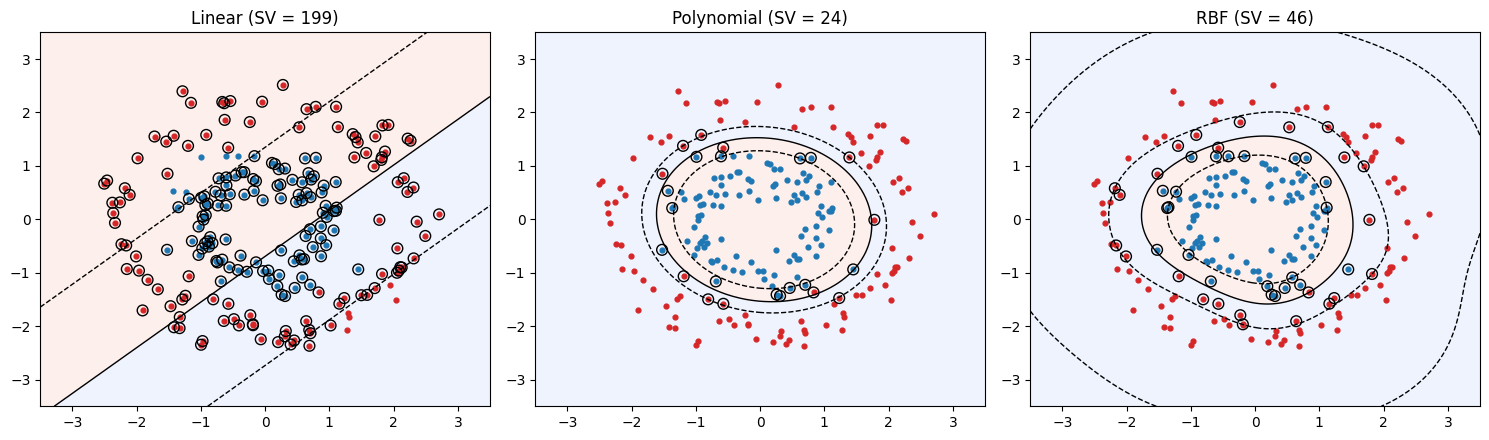

In [8]:
gx, gy = np.meshgrid(np.linspace(-3.5, 3.5, 200), np.linspace(-3.5, 3.5, 200))
grid = np.c_[gx.ravel(), gy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, m) in zip(axes, models.items()):
    Z = m.decision_function(grid).reshape(gx.shape)
    ax.contourf(gx, gy, Z > 0, alpha=0.15, cmap='coolwarm')
    ax.contour(gx, gy, Z, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'], linewidths=1)
    ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], c='tab:blue', s=12)
    ax.scatter(X_train[y_train == -1, 0], X_train[y_train == -1, 1], c='tab:red', s=12)
    sv = m.a > eps
    ax.scatter(X_train[sv, 0], X_train[sv, 1], s=60, facecolors='none', edgecolors='k')
    ax.set_title(f'{name} (SV = {sv.sum()})')
plt.tight_layout(); plt.show()

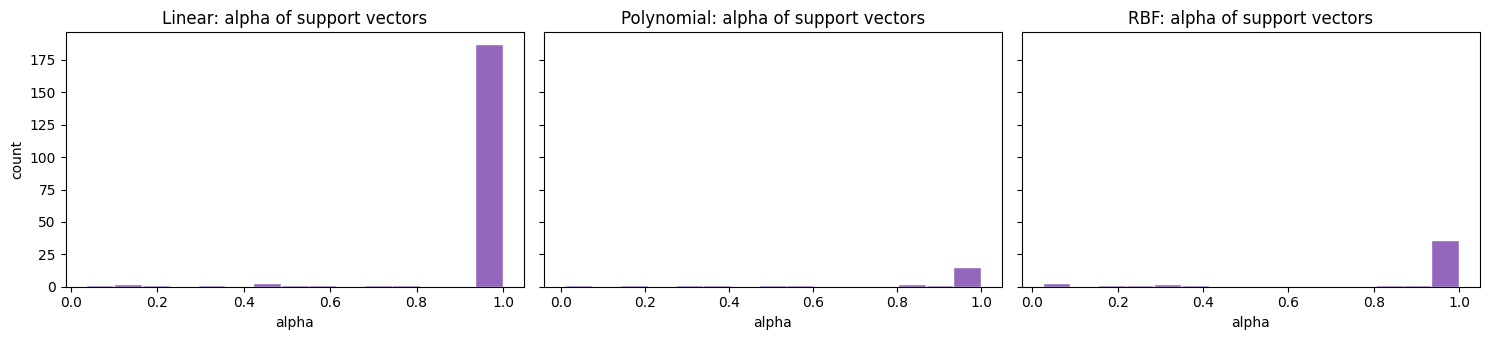

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    ax.hist(m.a[m.a > eps], bins=15, color='tab:purple', edgecolor='white')
    ax.set_title(f'{name}: alpha of support vectors'); ax.set_xlabel('alpha')
axes[0].set_ylabel('count')
plt.tight_layout(); plt.show()

In [10]:
print(f"{'gamma':>6s} {'Total SV':>9s} {'Train acc':>10s} {'Test acc':>9s}")
for g in [0.01, 0.1, 0.5, 2, 10]:
    m = KernelSVM(lambda A, B: rbf_kernel(A, B, gamma=g), C=1.0).fit(X_train, y_train)
    print(f'{g:6} {np.sum(m.a > eps):9d} {accuracy(y_train, m.predict(X_train)):10.3f} {accuracy(y_test, m.predict(X_test)):9.3f}')

 gamma  Total SV  Train acc  Test acc
  0.01       208      0.676     0.689
   0.1        81      0.990     1.000
   0.5        46      0.986     1.000
     2        60      0.990     0.989
    10       146      0.995     0.978


## Analysis
(Apne run ke numbers dekhke yahan 2-3 line apne words me likho.)

- **Linear kernel** circular data pe fail hota hai: accuracy lagbhag random ke paas aur zyadatar points support vector ban jaate hain, kyunki koi bhi line margin nahi bana paati.
- **Polynomial (degree 2)** circle ko quadratic boundary (ellipse) se separate karta hai, isliye is data pe kaafi achha chalta hai.
- **RBF** flexible local boundary banata hai. `gamma` bada karne pe boundary tight hoti hai aur support vectors badhte hain (overfit ka risk), chhota karne pe boundary smooth hoti hai.
- **Support vector count** model complexity ka indicator hai. Kam SV ka matlab simple, saaf boundary. Zyada SV ka matlab data kaafi overlap kar raha hai ya model zyada complex hai.
- **Bounded SV (alpha = C)** wo points hain jo margin ke andar ya galat side pe hain, margin SV (0 < alpha < C) exactly margin pe hain.